In [29]:
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

## Creación de un modelo de clasificación

In [30]:
# division de los datos en test y train

def data_split(musculo):
  data = pd.read_csv(f'/content/{musculo}', index_col=0)


  X = data.loc[:,['Max', 'Mean', 'Std','Median','RMS', 'SSI']]
  y = data.iloc[:, -1]

  from sklearn.model_selection import train_test_split
  X_train, X_val, y_train, y_val = train_test_split(X, y, test_size = 4, random_state = 1, stratify = y)

  return X_train, X_val, y_train, y_val

In [31]:
# ahora defino y entreno el modelo
#from sklearn.tree import DecisionTreeClassifier
#emg_model = DecisionTreeClassifier(random_state = 1)
#emg_model.fit(X_train, y_train)

In [32]:
# evalúo el modelo con el conjunto de validacion
#from sklearn.metrics import accuracy_score
#emg_model.fit(X_train, y_train)
#y_pred = emg_model.predict(X_val)
#acc = accuracy_score(y_val, y_pred)
#print(f'Accuracy: {acc}')

Ahora, intento alcanzar mas acc buscando la profundidad optima del arbol con un bucle

In [66]:
import numpy as np
from sklearn.metrics import accuracy_score

candidate_max_depth = np.linspace(1,10,10)

def get_acc(depth, X_train, X_val, y_train, y_val):
    model = DecisionTreeClassifier(max_depth = int(depth), random_state = 1)
    model.fit(X_train, y_train)
    preds_val = model.predict(X_val)
    acc = accuracy_score(y_val, preds_val)
    return(acc)

def busca_max_depth(candidate_max_depth, X_train, X_val, y_train, y_val):
  accs = []
  for max_depth in candidate_max_depth:
      acc = get_acc(max_depth, X_train, X_val, y_train, y_val)
      accs.append(acc)
  best_tree_depth = int(candidate_max_depth[accs.index(max(accs))])

  return best_tree_depth




In [81]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
import seaborn as sns

def entrenar_evaluar_modelo(musculo, random_state=1):
    # 1. Obtener los datos divididos
    X_train, X_val, y_train, y_val = data_split(musculo)

    # 2. Entrenar el modelo
    max_depth = busca_max_depth(candidate_max_depth, X_train, X_val, y_train, y_val)
    print(f'La mejor profundidad para el musculo {musculo} es: {max_depth}')
    modelo = DecisionTreeClassifier(max_depth=max_depth, random_state=random_state)
    modelo.fit(X_train, y_train)

    # 3. Predicción y métricas
    y_pred = modelo.predict(X_val)
    acc = accuracy_score(y_val, y_pred)
    print(f'La precisión alcanzada para el musculo {musculo} es {acc}')
    conf_matrix = confusion_matrix(y_val, y_pred)
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Sano', 'Enfermo'], yticklabels=['Sano', 'Enfermo'])
    plt.xlabel('Predicción')
    plt.ylabel('Real')
    plt.title(f'Matriz de Confusión ({musculo})')
    plt.show()

    return modelo, acc



La mejor profundidad para el musculo Biceps es: 4
La precisión alcanzada para el musculo Biceps es 1.0


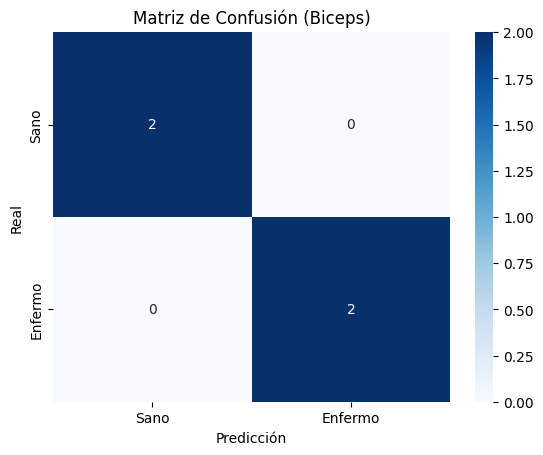

(DecisionTreeClassifier(max_depth=4, random_state=1), 1.0)

In [82]:

entrenar_evaluar_modelo('Biceps', random_state=1)

La mejor profundidad para el musculo Anterior Deltoid es: 2
La precisión alcanzada para el musculo Anterior Deltoid es 0.5


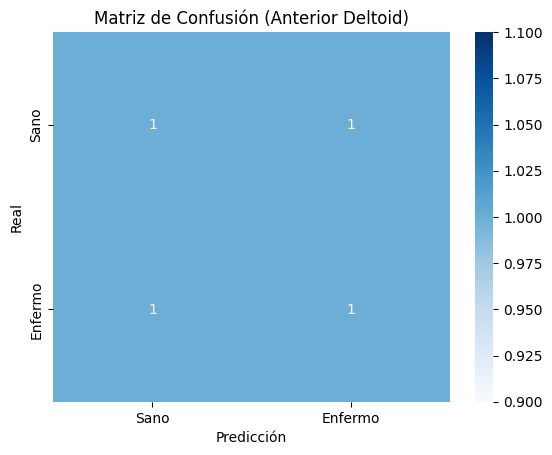

La mejor profundidad para el musculo Biceps es: 4
La precisión alcanzada para el musculo Biceps es 1.0


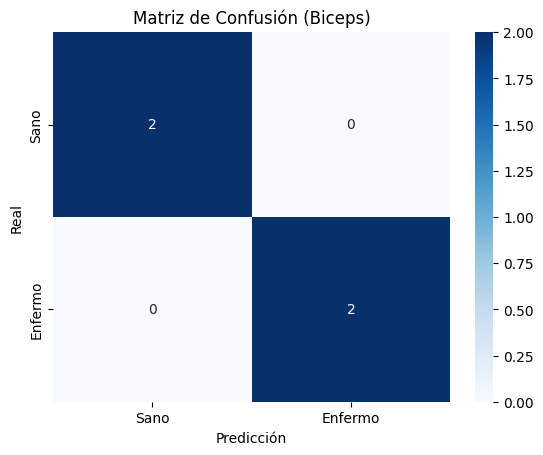

La mejor profundidad para el musculo Infraspinatus es: 2
La precisión alcanzada para el musculo Infraspinatus es 1.0


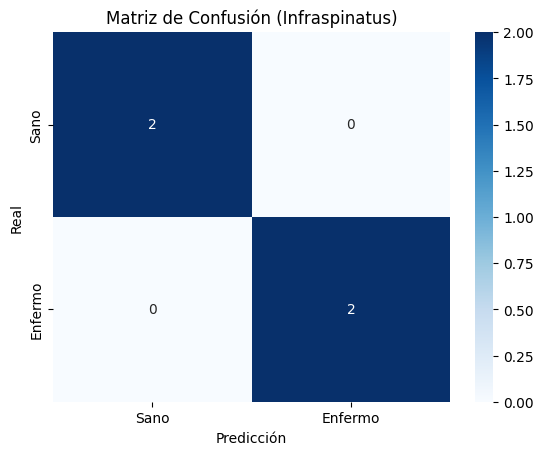

La mejor profundidad para el musculo Medial Deltoid es: 1
La precisión alcanzada para el musculo Medial Deltoid es 0.75


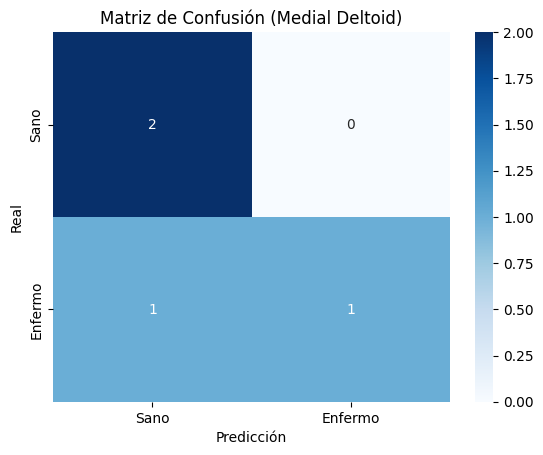

La mejor profundidad para el musculo Pectoralis Major es: 1
La precisión alcanzada para el musculo Pectoralis Major es 0.5


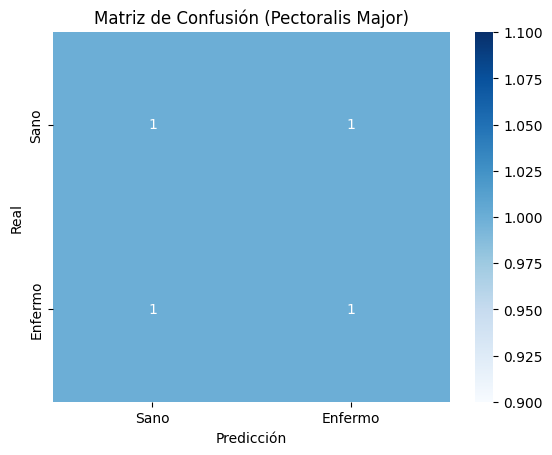

La mejor profundidad para el musculo Posterior Deltoid es: 1
La precisión alcanzada para el musculo Posterior Deltoid es 0.75


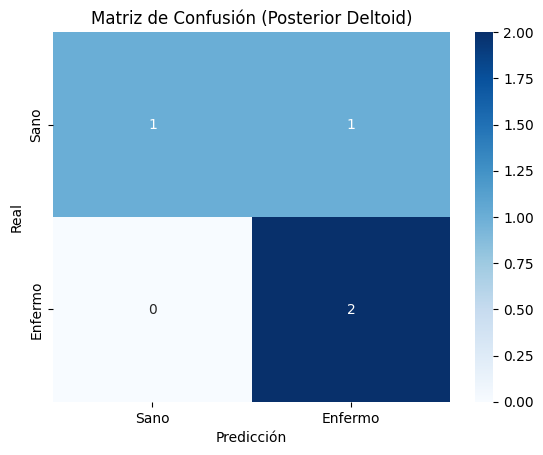

La mejor profundidad para el musculo Triceps es: 2
La precisión alcanzada para el musculo Triceps es 1.0


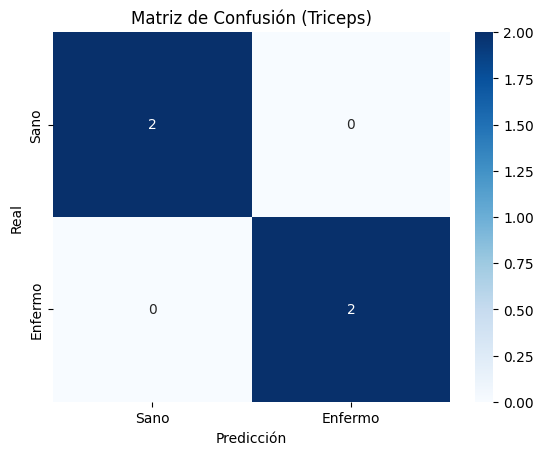

La mejor profundidad para el musculo Upper Trapezius es: 1
La precisión alcanzada para el musculo Upper Trapezius es 0.5


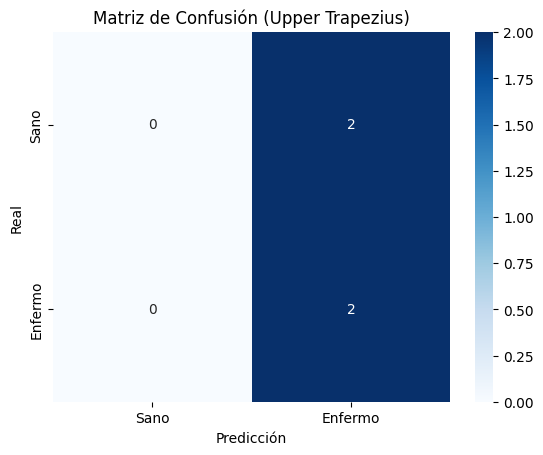

In [83]:
lista_musculos = ['Anterior Deltoid', 'Biceps', 'Infraspinatus','Medial Deltoid', 'Pectoralis Major', 'Posterior Deltoid', 'Triceps', 'Upper Trapezius']
acc_musc = []

modelo_ad, acc_ad = entrenar_evaluar_modelo('Anterior Deltoid', random_state=1)
acc_musc.append(acc_ad)

modelo_biceps, acc_biceps = entrenar_evaluar_modelo('Biceps', random_state=1)
acc_musc.append(acc_biceps)

modelo_infrasp, acc_infrasp = entrenar_evaluar_modelo('Infraspinatus', random_state=1)
acc_musc.append(acc_infrasp)

modelo_md, acc_md = entrenar_evaluar_modelo('Medial Deltoid', random_state=1)
acc_musc.append(acc_md)

modelo_pm, acc_pm = entrenar_evaluar_modelo('Pectoralis Major', random_state=1)
acc_musc.append(acc_pm)

modelo_pd, acc_pd = entrenar_evaluar_modelo('Posterior Deltoid', random_state=1)
acc_musc.append(acc_pd)

modelo_triceps, acc_triceps = entrenar_evaluar_modelo('Triceps', random_state=1)
acc_musc.append(acc_triceps)

modelo_ut, acc_ut = entrenar_evaluar_modelo('Upper Trapezius', random_state=1)
acc_musc.append(acc_ut)

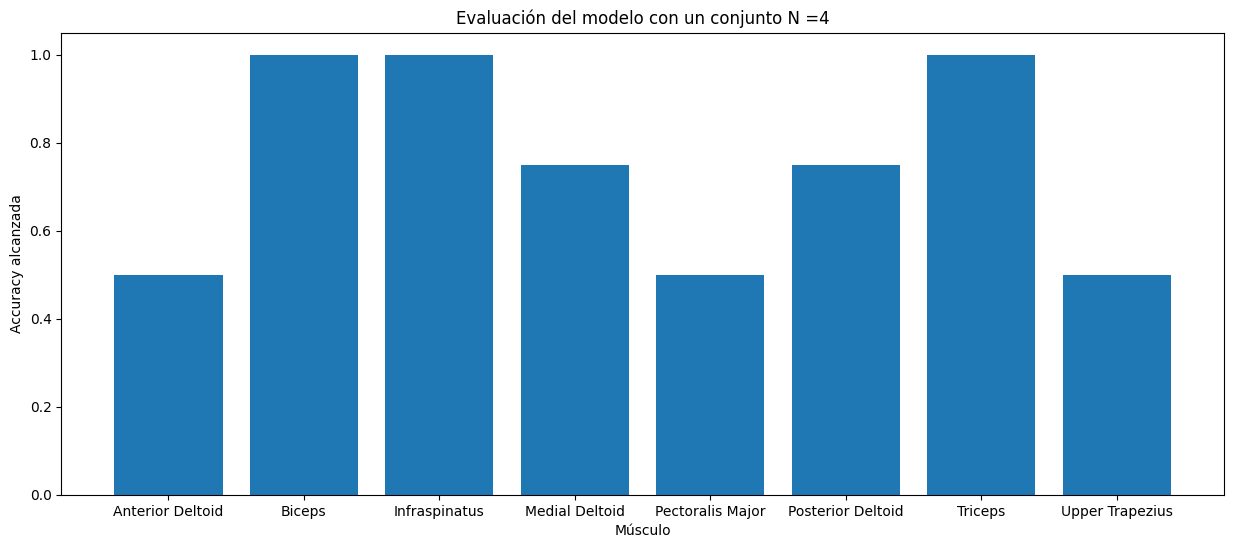

In [84]:


plt.figure(figsize=(15, 6))
plt.bar(lista_musculos, acc_musc)
plt.xlabel('Músculo')
plt.ylabel('Accuracy alcanzada')
plt.title('Evaluación del modelo con un conjunto N =4')
plt.show()